# 🎓 第3章 第3课：绩效比较与稳健性

**本节目标**：把七个因子放在同一张桌子上比较：

1. 年化收益、波动、Sharpe、NW t、最大回撤；
2. 累计净值与相关性；
3. 分区间稳健性：前半段有效的因子，后半段还灵吗？

对应原书 3.2~3.8 节的因子比较与研究建议。

In [1]:
import sys
from pathlib import Path

def _find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'src' / 'factor_zero').exists():
            return p
    raise FileNotFoundError('找不到仓库根目录，请从仓库内启动 notebook')
ROOT = _find_root()
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from factor_zero.data import load_ashare_panel
from factor_zero.factors import build_factor_returns
from factor_zero.statistics import factor_summary, nw_t_stat
from factor_zero.sorting import long_short_factor, monotonicity_test

FACTOR_NAMES = ['MKT', 'SMB', 'HML', 'WML', 'RMW', 'CMA', 'TURN']
FACTOR_CN = {'MKT': '市场', 'SMB': '规模', 'HML': '价值',
             'WML': '动量', 'RMW': '盈利', 'CMA': '投资', 'TURN': '换手率'}

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'DejaVu Sans']
print('✅ 环境就绪，开始学习！')

✅ 环境就绪，开始学习！


In [2]:
panel = load_ashare_panel()
factors = build_factor_returns(panel, n_groups=10)
rows = {}
for col in factors.columns:
    s = factor_summary(factors[col].dropna())
    if s:
        rows[col] = s
perf = pd.DataFrame(rows).T
perf.index = [f'{k}（{FACTOR_CN[k]}）' for k in perf.index]
perf.columns = ['年化收益', '年化波动', 'Sharpe', 'NW t', '最大回撤', '胜率']
perf.round(4)

,年化收益,年化波动,Sharpe,NW t,最大回撤,胜率
MKT（市场）,0.0986,0.1744,0.5654,1.6306,-0.2577,0.5244
SMB（规模）,0.2510,0.2664,0.9421,2.0356,-0.4500,0.5976
HML（价值）,-0.2082,0.2830,-0.7356,-2.1130,-0.8511,0.3902
WML（动量）,0.1957,0.3543,0.5524,1.4069,-0.3914,0.6286
RMW（盈利）,0.1009,0.2316,0.4359,1.1690,-0.4335,0.5732
CMA（投资）,0.0297,0.1514,0.1963,0.4578,-0.4239,0.5488
TURN（换手率）,-0.0533,0.3153,-0.1689,-0.4272,-0.8281,0.4756


### 怎么读绩效表？

- **年化收益 / 年化波动**：月度均值/标准差 × 12 / × √12；
- **Sharpe**：年化收益 ÷ 年化波动（未减无风险利率，示意）；
- **NW t**：Newey-West 调整后的 t 值，|t| > 2 才显著；
- **最大回撤**：累计净值从高点到低点的最大跌幅；
- **胜率**：因子收益为正的月份占比。

> 单看收益不够：高收益可能伴随高波动/大回撤。四个指标要一起看。

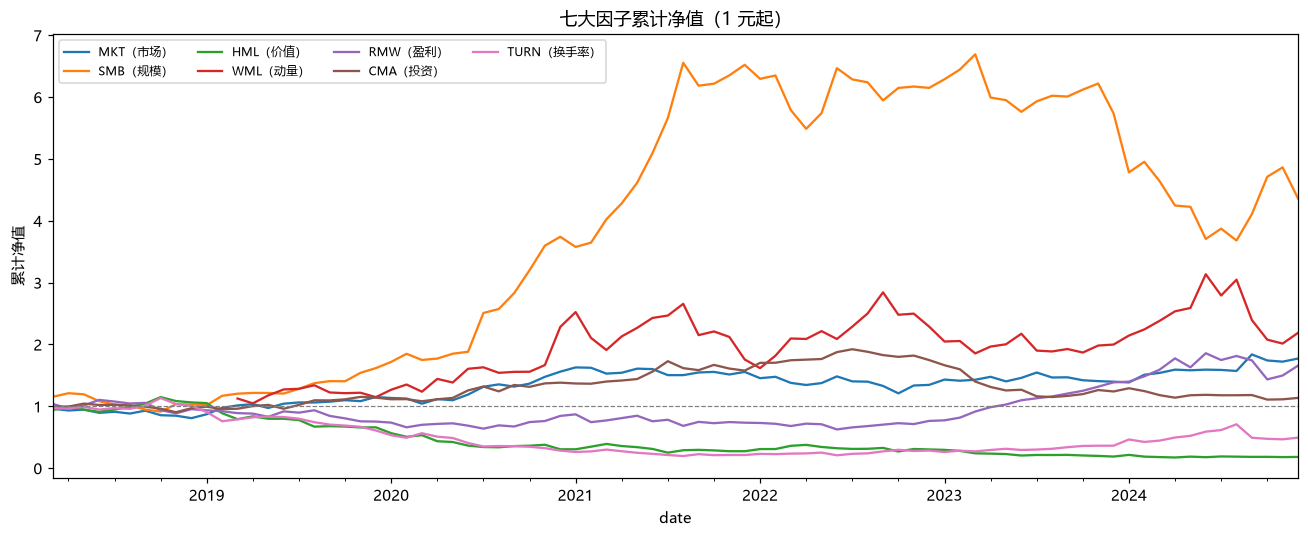

In [3]:
nav = (1 + factors).cumprod()
fig, ax = plt.subplots(figsize=(12, 5))
for col in FACTOR_NAMES:
    nav[col].dropna().plot(ax=ax, label=f'{col}（{FACTOR_CN[col]}）')
ax.axhline(1, color='gray', lw=.8, ls='--')
ax.set_title('七大因子累计净值（1 元起）')
ax.set_ylabel('累计净值')
ax.legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

## 相关性：因子之间是不是“亲戚”？

相关性高 → 可能重复；相关性低 → 组合起来更分散。
但相关性不是全部：两个因子可能在不同区间轮换表现。

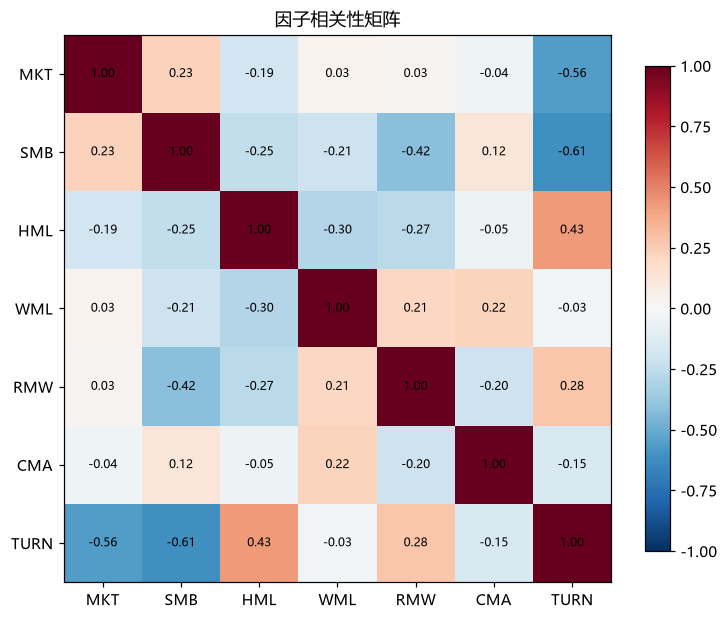

In [4]:
corr = factors.corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im, ax=ax, shrink=.8)
ax.set_title('因子相关性矩阵')
plt.tight_layout(); plt.show()

## 分区间稳健性：前半段 vs 后半段

把样本一分为二，看每个因子的年化收益符号是否一致。
**一个因子只有在不同区间都站得住，才更可信。**

In [5]:
mid = len(factors) // 2
first = factors.iloc[:mid].mean() * 12
second = factors.iloc[mid:].mean() * 12
stab = pd.DataFrame({'前半段': first, '后半段': second}) * 100
stab.index = [f'{k}（{FACTOR_CN[k]}）' for k in stab.index]
stab['符号一致'] = np.sign(stab['前半段']) == np.sign(stab['后半段'])
stab.round(2)

,前半段,后半段,符号一致
MKT（市场）,13.45,6.27,True
SMB（规模）,54.98,-4.79,False
HML（价值）,-35.67,-5.96,True
WML（动量）,43.89,2.37,True
RMW（盈利）,-4.73,24.92,False
CMA（投资）,17.16,-11.22,False
TURN（换手率）,-41.65,31.00,False


## 因子冗余：正交化看增量

以 HML（价值）和 SMB（规模）为例：把 HML 对 SMB 回归，残差就是 HML 中
不能被 SMB 解释的“纯增量”。如果残差与 SMB 的相关性接近 0，说明正交化成功。

In [6]:
x = factors['SMB'].dropna()
y = factors['HML'].reindex(x.index).dropna()
x = x.reindex(y.index)
coef = np.polyfit(x, y, 1)
resid = y - (coef[0] * x + coef[1])
print(f'HML 与 SMB 原始相关性: {np.corrcoef(x, y)[0, 1]:.3f}')
print(f'正交化后残差与 SMB 相关性: {np.corrcoef(x, resid)[0, 1]:.6f}')
print('→ 残差就是 HML 的增量信息，可用于构建“纯净”价值因子')

HML 与 SMB 原始相关性: -0.250
正交化后残差与 SMB 相关性: 0.000000
→ 残差就是 HML 的增量信息，可用于构建“纯净”价值因子


## ✋ 试一试

1. 把样本按“2018-2021 / 2022-2024”重新切分，结论变了吗？
2. 把 `factor_summary` 的 `periods_per_year` 改成 252（日频），数字怎么变？
3. 换一个因子做正交化（例如 WML 对 MKT），残差相关性是多少？

## ✅ 本节小结

- 因子比较要同时看收益、波动、Sharpe、t 值、最大回撤、胜率；
- 相关性矩阵判断冗余，正交化看增量；
- 分区间稳健性是防止“只在一段样本里有效”的关键；
- 示例面板为教学数据，结论不代表真实 A 股。

> 下一章：把因子组合成多因子模型（FF3、Carhart4、FF5……），并比较谁更好。